**Building a Siamese model (using face pairs) but with a ResNet inspired architecture:**

In [1]:
import torch
import torchvision
from torch.utils.data import Dataset, DataLoader, TensorDataset, Subset
from torchvision import transforms
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from typing import List, Dict

Label Desc: different images and the general category they belong to

In [2]:
root_path = "../../data/faces"
label_desc = pd.read_csv(f"{root_path}/Dataset.csv")
label_desc.head(4)

,id,label
0,Robert Downey Jr_87.jpg,Robert Downey Jr
1,Lisa Kudrow_64.jpg,Lisa Kudrow
2,Ellen Degeneres_34.jpg,Ellen Degeneres
3,Billie Eilish_3.jpg,Billie Eilish


In [3]:
# generate all the general labels and then store them in a list
labels = label_desc['label'].unique().tolist()

# now, we do not want to index images to general label using a pandas dataframe, so we will use and create a dictionary
label_dict = {k:v for k,v in zip(label_desc['id'].values, label_desc['label'].values)}

visualise some of the images

(160, 160, 3)


(np.float64(-0.5), np.float64(159.5), np.float64(159.5), np.float64(-0.5))

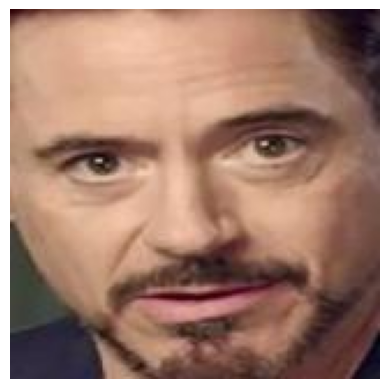

In [6]:
image = Image.open(f"{root_path}/Faces/Faces/Robert Downey Jr_87.jpg")
image = np.array(image)
print(image.shape)
plt.imshow(image)
plt.axis("off")

In [7]:
image = Image.open(f"{root_path}/Faces/Faces/Robert Downey Jr_87.jpg")
to_tensor = transforms.ToTensor()
image_tensor = to_tensor(image)

In [8]:
image_tensor.shape

torch.Size([3, 160, 160])

Ok, now need to process the datasets so as to build image pairs for contrastive loss
- 15 identities for training
- 10 identities for validation
- 6 identities for testing

In [12]:
import random

In [13]:
random.seed(42)
unique_identities = label_desc['label'].unique().tolist()
random.shuffle(unique_identities)
training_identities = unique_identities[:15]
val_identities = unique_identities[15:25]
test_identities = unique_identities[25:]

# now need to get the images that correspond to these identities.

In [16]:
all_images = os.listdir(f"{root_path}/Faces/Faces/")

In [39]:
training_images = [
    image

    for images in [
    list(filter(lambda x: identity in x, all_images))
    for identity in training_identities]
    
    for image in images
]

val_images = [
    image

    for images in [
    list(filter(lambda x: identity in x, all_images))
    for identity in val_identities
    ]

    for image in images
]

test_images = [
    image
    
    for images in [
    list(filter(lambda x: identity in x, all_images))
    for identity in test_identities
    ]

    for image in images
]

In [43]:
print(f"Training Images: {len(training_images)} | Val Images: {len(val_images)} | Test images: {len(test_images)}")

Training Images: 1284 | Val Images: 753 | Test images: 525


Build the Dataset class

In [45]:
np.random.choice?

Signature: np.random.choice(a, size=None, replace=True, p=None)
Docstring:
choice(a, size=None, replace=True, p=None)

Generates a random sample from a given 1-D array

.. versionadded:: 1.7.0

.. note::
    New code should use the `~numpy.random.Generator.choice`
    method of a `~numpy.random.Generator` instance instead;
    please see the :ref:`random-quick-start`.

.. warning::
    This function uses the C-long dtype, which is 32bit on windows
    and otherwise 64bit on 64bit platforms (and 32bit on 32bit ones).
    Since NumPy 2.0, NumPy's default integer is 32bit on 32bit platforms
    and 64bit on 64bit platforms.


Parameters
----------
a : 1-D array-like or int
    If an ndarray, a random sample is generated from its elements.
    If an int, the random sample is generated as if it were ``np.arange(a)``
size : int or tuple of ints, optional
    Output shape.  If the given shape is, e.g., ``(m, n, k)``, then
    ``m * n * k`` samples are drawn.  Default is None, in which case a


In [73]:
class FacesDataset(Dataset):
    def __init__(self, root_dir: str, files: List[str], label_dict: Dict[str, str], pairs_per_anchor:int=5, transforms=None):
        super().__init__()
        self.root_dir = root_dir + "/Faces/Faces"
        self.files = files
        self.transforms = transforms
        self.labels = list(map(lambda x: label_dict.get(x), files))
        self.unique_labels = list(set(self.labels))

        self.label_dict = label_dict
        self.pairs_per_anchor = pairs_per_anchor
        # building numeric labels

        self.numeric_labels_all = np.array([self.unique_labels.index(x) for x in self.labels])

        self.pairImages, self.pairLabels = self.build_pairs()
    
    def __len__(self):
        return len(self.pairLabels)
    
    def __getitem__(self, index):
        if self.transforms:
            if self.pairImages[index].ndim == 5:
                img1, img2 = self.pairImages[index][:, 0], self.pairImages[index][:, 1]
                img1, img2 = self.transforms(torch.tensor(img1)), self.transforms(torch.tensor(img2))
                pair = torch.stack((img1, img2), dim=1)
                return pair, self.pairLabels[index]
            elif self.pairImages[index].ndim == 4:
                img1, img2 = self.pairImages[index][0,:], self.pairImages[index][1,:]
                img1, img2 = self.transforms(torch.tensor(img1)), self.transforms(torch.tensor(img2))
                pair = torch.stack((img1, img2), dim=0)
                return pair, self.pairLabels[index]
        return torch.tensor(self.pairImages[index]), self.pairLabels[index]
    
    def build_pairs(self):
        # use the numeric labels and images to build the pairs
        pairImages = []
        pairLabels = []

        # for each label in the distinct numeric labels, get the image indices that correspond to that particular label
        unique_numeric_labels = list(range(len(self.unique_labels)))

        similar_img_indices = [np.where(self.numeric_labels_all == label)[0] for label in unique_numeric_labels]

        # dissimilar image indices
        dissimilar_img_indices = [np.where(self.numeric_labels_all != label)[0] for label in unique_numeric_labels]

        np.random.seed(42)

        to_tensor = transforms.ToTensor()

        for i, img_path in enumerate(self.files):
            img = Image.open(f"{self.root_dir}/{img_path}")
            img_label = self.numeric_labels_all[i]

            img = to_tensor(img)

            # fetch a similar image
            # need to also ensure that we never fetch a positive that is the same image as the anchor
            
            similar_img_indices_temp = similar_img_indices[img_label]
            # filter out the current anchor
            similar_img_indices_temp = similar_img_indices_temp[similar_img_indices_temp != i]

            # if len(similar_img_indices_temp < self.pairs_per_anchor):
            #     continue

            similar_idx = np.random.choice(similar_img_indices_temp, self.pairs_per_anchor, replace=False)

            for j in range(self.pairs_per_anchor):
                sim_img = Image.open(f"{self.root_dir}/{self.files[similar_idx[j]]}")
                sim_img = to_tensor(sim_img)
                pairImages.append((img, sim_img))
                pairLabels.append(1)

            dissimilar_idx = np.random.choice(dissimilar_img_indices[img_label], self.pairs_per_anchor, replace=False)

            for j in range(self.pairs_per_anchor):
                disim_img = Image.open(f"{self.root_dir}/{self.files[dissimilar_idx[j]]}")
                disim_img = to_tensor(disim_img)
                pairImages.append((img, disim_img))
                pairLabels.append(0)
        
        return np.array(pairImages), np.array(pairLabels)

Testing the Dataset Class:

In [74]:
pairs_dataset = FacesDataset(root_dir=root_path, files=training_images, label_dict = label_dict)

In [75]:
np.random.seed(4122)
query_indices = np.random.choice(np.arange(len(training_images)), size=10)

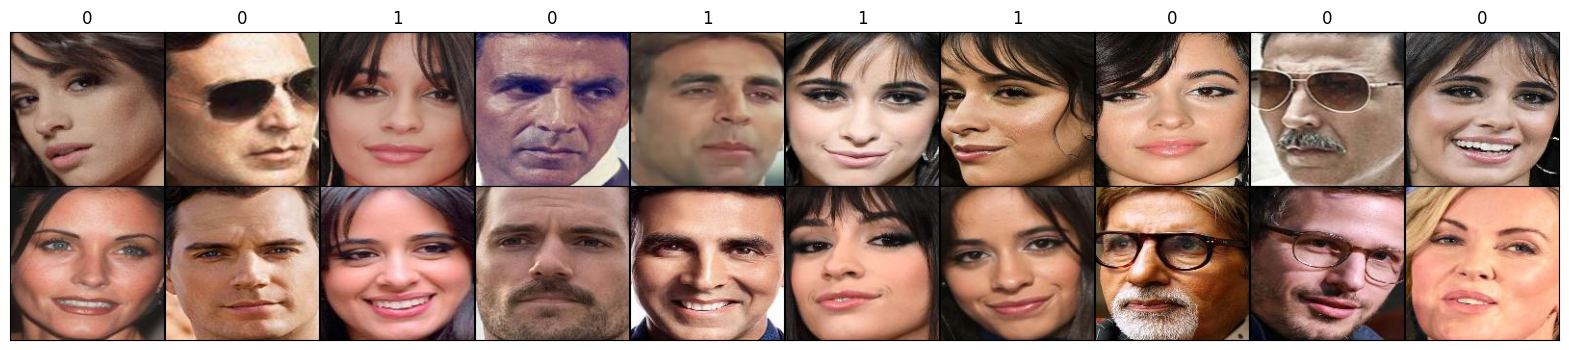

In [82]:
fig, ax = plt.subplots(2, 10, figsize=(20,4))
fig.subplots_adjust(hspace=0, wspace=0)

for i in range(2):
    for j in range(10):
        ax[i,j].imshow(pairs_examples[0].clone().numpy()[j][i].transpose(1,2,0))
        if i == 0:
            ax[i,j].set_title(pairs_examples[1][j])
        ax[i,j].set_xticks([]); ax[i,j].set_yticks([]);

Transformations and building the dataloader:
- Transforms to help with face recognition:
  - Color jitter, random horizontal flipping 

Testing out different transforms...

In [83]:
transforms.RandomAffine?

Init signature:
transforms.RandomAffine(
    degrees,
    translate=None,
    scale=None,
    shear=None,
    interpolation=<InterpolationMode.NEAREST: 'nearest'>,
    fill=0,
    center=None,
)
Docstring:     
Random affine transformation of the image keeping center invariant.
If the image is torch Tensor, it is expected
to have [..., H, W] shape, where ... means an arbitrary number of leading dimensions.

Args:
    degrees (sequence or number): Range of degrees to select from.
        If degrees is a number instead of sequence like (min, max), the range of degrees
        will be (-degrees, +degrees). Set to 0 to deactivate rotations.
    translate (tuple, optional): tuple of maximum absolute fraction for horizontal
        and vertical translations. For example translate=(a, b), then horizontal shift
        is randomly sampled in the range -img_width * a < dx < img_width * a and vertical shift is
        randomly sampled in the range -img_height * b < dy < img_height * b. Will not 

In [84]:
image = Image.open(f"{root_path}/Faces/Faces/Robert Downey Jr_87.jpg")
image = to_tensor(image)

In [85]:
# random affine..
ra = transforms.RandomAffine(
        degrees=8,
        translate=(0.05, 0.05),
        scale=(0.92, 1.08),
        shear=3
    )
image_ra = ra(image)

(np.float64(-0.5), np.float64(159.5), np.float64(159.5), np.float64(-0.5))

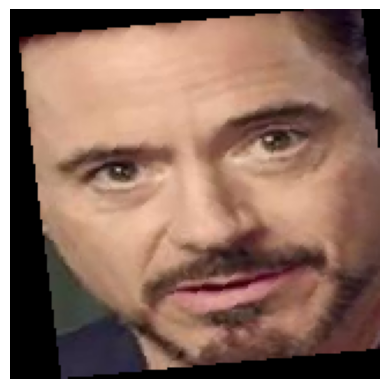

In [90]:
plt.imshow(image_ra.numpy().transpose(1,2,0))
plt.axis("off")

(np.float64(-0.5), np.float64(159.5), np.float64(159.5), np.float64(-0.5))

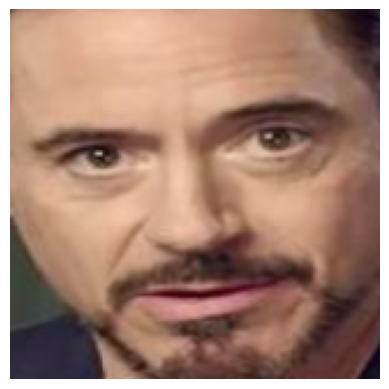

In [91]:
rc = transforms.RandomResizedCrop(
    size=160,
    scale=(0.85, 1.0),
    ratio=(0.9, 1.1)
)

image_rc = rc(image)

plt.imshow(image_rc.numpy().transpose(1,2,0))
plt.axis("off")

(np.float64(-0.5), np.float64(159.5), np.float64(159.5), np.float64(-0.5))

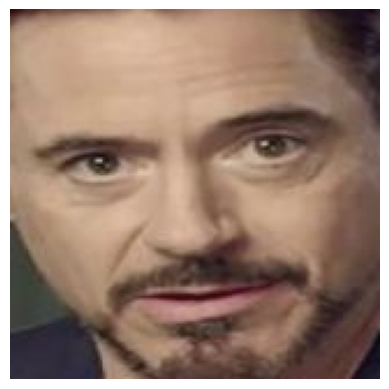

In [94]:
gb = transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.15,
        hue=0.03
    )

image_gb = gb(image)

plt.imshow(image_gb.numpy().transpose(1,2,0))
plt.axis("off")

(np.float64(-0.5), np.float64(159.5), np.float64(159.5), np.float64(-0.5))

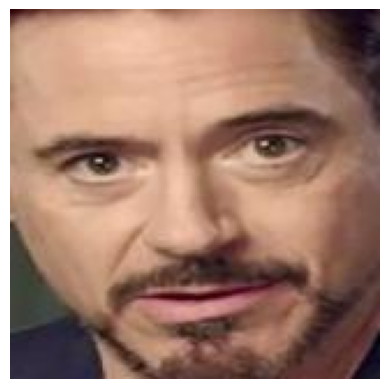

In [95]:
gb = transforms.RandomApply([
        transforms.Lambda(
            lambda x: torch.clamp(
                x + torch.randn_like(x) * 0.015,
                0,
                1
            )
        )
    ], p=0.2)

image_gb = gb(image)

plt.imshow(image_gb.numpy().transpose(1,2,0))
plt.axis("off")

In [96]:
train_transforms = transforms.Compose([
    transforms.RandomAffine(
        degrees=8,
        translate=(0.05, 0.05),
        scale=(0.92, 1.08),
        shear=3
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.15,
        hue=0.03
    ),
    transforms.RandomApply([
        transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.2))
    ], p=0.2),
])

In [ ]:
pairs_train = FacesDataset(root_dir=root_path, files= training_images, label_dict=label_dict, transforms=train_transforms)

In [121]:
pairs_val = FacesDataset(root_dir=root_path, files= val_images, label_dict=label_dict)
pairs_test = FacesDataset(root_dir=root_path, files= test_images, label_dict=label_dict)

In [100]:
np.random.seed(508)
query_indices = np.random.choice(np.arange(len(training_images)), size=10)
pairs_examples = pairs_train[query_indices.tolist()]

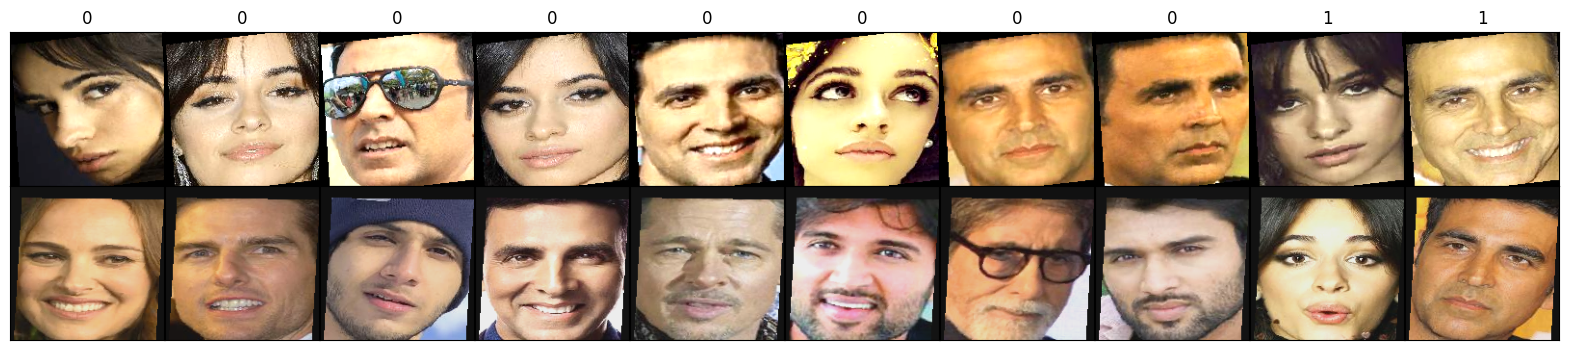

In [101]:
fig, ax = plt.subplots(2,10, figsize=(20,4))
fig.subplots_adjust(hspace=0,wspace=0)
for i in range(2):
    for j in range(10):
        ax[i,j].imshow(pairs_examples[0].clone().numpy()[j][i].transpose(1,2,0))
        if i == 0:
            ax[i,j].set_title(pairs_examples[1][j])
        ax[i,j].set_xticks([]); ax[i,j].set_yticks([]);

In [ ]:
pairs_train_dl = DataLoader(pairs_train, batch_size=64, shuffle=True)

In [122]:
pairs_val_dl = DataLoader(pairs_val, batch_size=64)
pairs_test_dl = DataLoader(pairs_test, batch_size=64)

In [123]:
z = next(iter(pairs_val_dl))

In [104]:
z[0].shape

torch.Size([64, 2, 3, 160, 160])

In [124]:
z[0].shape

torch.Size([64, 2, 3, 160, 160])

In [125]:
z[1].shape

torch.Size([64])

**Build the Model**
- Contrastive Loss training

In [106]:
import torch.nn as nn
from utils.early_stopping import EarlyStopping
import torch.nn.functional as F

In [131]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, stride: int=1):
        super().__init__()

        self.main_path = nn.Sequential(
            nn.Conv2d(
                in_channels = in_channels, 
                out_channels = out_channels,
                kernel_size = 3,
                stride = stride,
                padding = 1,
                bias = False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),

            nn.Conv2d(
                in_channels = out_channels,
                out_channels = out_channels,
                kernel_size = 3,
                stride = 1,
                padding = 1,
                bias = False
            ),
            nn.BatchNorm2d(out_channels)
        )

        # the residual a nd main paths must have the same shape before addition
        if stride != 1 or in_channels != out_channels:
            self.skip_path = nn.Sequential(
                nn.Conv2d(
                    in_channels = in_channels,
                    out_channels = out_channels,
                    kernel_size = 1,
                    stride = stride,
                    bias = False
                ),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.skip_path = nn.Identity()
        
        self.activation = nn.ReLU()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        residual = self.skip_path(x)
        features = self.main_path(x)

        return self.activation(features + residual)

class ResNetEmbeddingNet(nn.Module):
    """
        ResNet inspired embedding network for siamese learning

        for a 160x160 input:
             -> (N, 3, 160, 160)
             -> (N, 32, 80, 80)
             -> (N, 64, 40, 40),
             -> (N, 128, 20, 20)
             -> (N, 256, 10, 10)
             -> (N, embedding_dim)
    """
    def __init__(self, embedding_dim: int = 128):
        super().__init__()

        self.feature_extractor = nn.Sequential(
            ResidualBlock(
                in_channels=3,
                out_channels = 32,
                stride = 2
            ),
            ResidualBlock(
                in_channels = 32,
                out_channels = 64,
                stride = 2
            ),
            ResidualBlock(
                in_channels = 64,
                out_channels = 128,
                stride = 2
            ),
            ResidualBlock(
                in_channels = 128,
                out_channels = 256,
                stride = 2
            )
        )

        self.embedding_head = nn.Sequential(
            nn.AdaptiveAvgPool2d(output_size=1),
            nn.Flatten(),
            nn.Linear(
                in_features=256,
                out_features = embedding_dim
            )
        )

        self.apply(self._init_weights)
    
    def encode(self, x:torch.Tensor) -> torch.Tensor:
        features = self.feature_extractor(x)
        embeddings = self.embedding_head(features)

        # put every embedding on the unit hypersphere
        return F.normalize(
            embeddings,
            p = 2,
            dim = 1
        )
    
    def forward(self, img1, img2) -> torch.Tensor:
        images = torch.cat([img1, img2], dim=0)
        embeddings = self.encode(images)
        featsA, featsB = embeddings.chunk(2, dim=0)
        return featsA, featsB
    
    @staticmethod
    def _init_weights(module: nn.Module) -> None:
        if isinstance(module, nn.Conv2d):
            nn.init.kaiming_normal_(
                module.weight
            )
            
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        
        elif isinstance(module, nn.Linear):
            nn.init.kaiming_normal_(
                module.weight
            )
            nn.init.zeros_(module.bias)

In [132]:
# the loss function
class CosineContrastiveLoss(nn.Module):
    def __init__(self, margin:float=0.8):
        super().__init__()
        self.margin = margin
    
    def forward(self, embedding1, embedding2, targets):
        targets = targets.float().view(-1) # flattening the targets

        similarity = F.cosine_similarity(
            embedding1,
            embedding2,
            dim=1
        )

        cosine_distance = 1.0 - similarity

        positive_loss = targets * cosine_distance.square()

        negative_loss = (
            1.0 - targets
        ) * F.relu(
            self.margin - cosine_distance
        ).square()

        return (positive_loss + negative_loss).mean()

In [133]:
device = torch.device('mps' if torch.mps.is_available() else 'cpu')
model = ResNetEmbeddingNet().to(device)
criterion = CosineContrastiveLoss(margin = 0.5)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)

# get a scheduler to reduce the learning rate on plateau
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=3, factor=0.5, min_lr=1e-6)

early_stopper = EarlyStopping(
    patience=12,
    min_delta = 1e-4,
    checkpoint_path = 'resnet.pt',
    restore_best_weights=True
)

# write the training loop

def train(epochs):
    train_loss = [0] * epochs
    val_loss = [0] * epochs

    for epoch in range(epochs):
        model.train()
        for x_batch, y_batch in pairs_train_dl:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            # forward pass
            img1, img2 = x_batch[:, 0], x_batch[:, 1]

            optimizer.zero_grad()
            embedding1, embedding2 = model(img1, img2)

            # compute the loss
            loss = criterion(embedding1, embedding2, y_batch)
            #backprop
            loss.backward()
            # optimization
            optimizer.step()


        # evaluation
        model.eval()
        with torch.no_grad():
            for x_batch, y_batch in pairs_val_dl:
                x_batch, y_batch = x_batch.to(device), y_batch.to(device)
                img1, img2 = x_batch[:, 0], x_batch[:, 1]
                # forward pass
                embedding1, embedding2 = model(img1, img2)

                loss = criterion(embedding1, embedding2, y_batch)

                val_loss[epoch] += loss.item() * y_batch.shape[0]
            
            val_loss[epoch] /= len(pairs_val_dl.dataset)
        
        with torch.no_grad():
            for x_batch, y_batch in pairs_train_dl:
                x_batch, y_batch = x_batch.to(device), y_batch.to(device)
                img1, img2 = x_batch[:, 0], x_batch[:, 1]
                # forward pass
                embedding1, embedding2 = model(img1, img2)

                loss = criterion(embedding1, embedding2, y_batch)

                train_loss[epoch] += loss * y_batch.shape[0]

            train_loss[epoch] /= len(pairs_train_dl.dataset)
        
        current_lr = optimizer.param_groups[0]["lr"]

        print(f"Epoch: {epoch+1}| Train Loss: {train_loss[epoch]} | Val Loss: {val_loss[epoch]} | LR: {current_lr}")

        scheduler.step(val_loss[epoch])
        early_stopper(val_loss[epoch], model, optimizer, epoch)

        if early_stopper.should_stop:
            break
    
    return train_loss, val_loss

In [134]:
z = next(iter(pairs_val_dl))

In [135]:
hist = train(30)

Epoch: 1| Train Loss: 0.05822821706533432 | Val Loss: 0.06387848136513673 | LR: 0.0003
Metric improved to 0.0639. Checkpoint saved at 0
Epoch: 2| Train Loss: 0.05062329024076462 | Val Loss: 0.05491449946604402 | LR: 0.0003
Metric improved to 0.0549. Checkpoint saved at 1
Epoch: 3| Train Loss: 0.045575473457574844 | Val Loss: 0.05191019131724103 | LR: 0.0003
Metric improved to 0.0519. Checkpoint saved at 2
Epoch: 4| Train Loss: 0.03867151960730553 | Val Loss: 0.04587106159226511 | LR: 0.0003
Metric improved to 0.0459. Checkpoint saved at 3
Epoch: 5| Train Loss: 0.033185940235853195 | Val Loss: 0.03987246015434404 | LR: 0.0003
Metric improved to 0.0399. Checkpoint saved at 4
Epoch: 6| Train Loss: 0.029233409091830254 | Val Loss: 0.03877749747805703 | LR: 0.0003
Metric improved to 0.0388. Checkpoint saved at 5
Epoch: 7| Train Loss: 0.029048940166831017 | Val Loss: 0.040046294472844475 | LR: 0.0003
No improvement for 1 epoch(s)
Epoch: 8| Train Loss: 0.02490401268005371 | Val Loss: 0.040125

Test out the resnet model

In [137]:
np.random.seed(42)

query_indices = np.random.choice(np.arange(len(pairs_test)), size=10)
pairs_test_examples = pairs_test[query_indices.tolist()]

In [139]:
pairs_test_examples[0].shape

torch.Size([10, 2, 3, 160, 160])

In [143]:
a,b =pairs_test_examples[0][1]

In [144]:
a.shape

torch.Size([3, 160, 160])

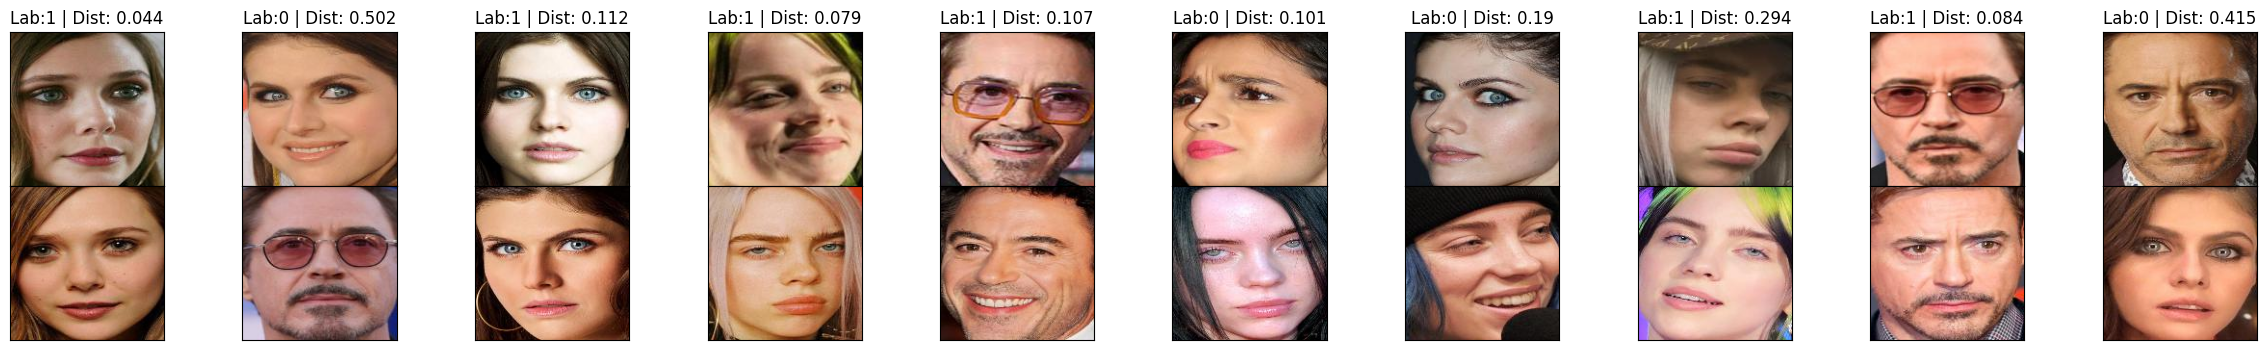

In [146]:
fig, ax = plt.subplots(2, 10, figsize=(30,4))
fig.subplots_adjust(hspace=0, wspace=0)
model.eval()
for i in range(2):
    for j in range(10):
        ax[i,j].imshow(pairs_test_examples[0].clone().numpy()[j][i].transpose(1,2,0))
        if i ==0:
            with torch.no_grad():
                img1, img2 = pairs_test_examples[0][j]
                emb1, emb2 = model(img1.unsqueeze(0).to(device), img2.unsqueeze(0).to(device))
                similarity = F.cosine_similarity(
                                    emb1,
                                    emb2,
                                    dim=1
                                ).item()
                ax[i,j].set_title(f"Lab:{pairs_test_examples[1][j]} | Dist: {round(1 - similarity,3)}")
        ax[i,j].set_xticks([]); ax[i,j].set_yticks([]);        



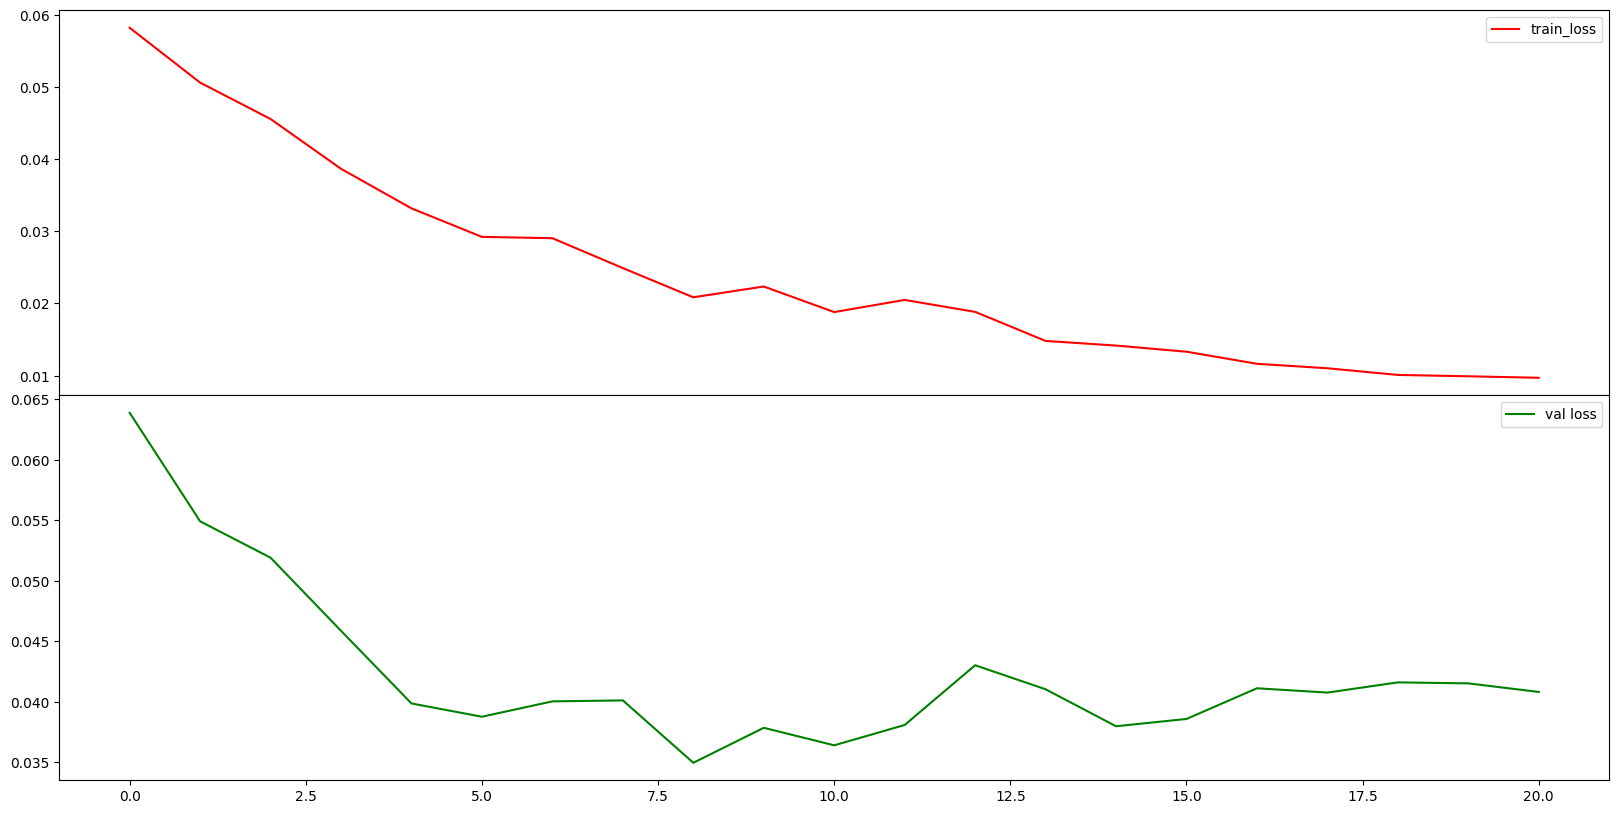

In [161]:
train_loss = list(map(lambda x: float(x), hist[0]))
val_loss = hist[1]

fig, ax = plt.subplots(2,1,figsize=(20,10),sharex=True)
fig.subplots_adjust(hspace=0)
ax[0].plot(train_loss[:21], color='red', label='train_loss')
ax[1].plot(val_loss[:21], color='green', label='val loss')
ax[0].legend(); ax[1].legend()

In [150]:
hist[1]

[0.06387848136513673,
 0.05491449946604402,
 0.05191019131724103,
 0.04587106159226511,
 0.03987246015434404,
 0.03877749747805703,
 0.040046294472844475,
 0.040125621182430946,
 0.03497463434657569,
 0.037862194263206854,
 0.03641680450157657,
 0.038096456150530505,
 0.043029159800227416,
 0.04104540914020057,
 0.037991457977697034,
 0.03859316805009031,
 0.04112648955616818,
 0.04077276602723842,
 0.0416141152381897,
 0.0415321335196495,
 0.04082254821442038,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0]